## Imports

In [1]:
from weather_pipeline.backends import get_backend
from weather_pipeline.datasource import ArraylakeERA5Source, open_era5_repo
from weather_pipeline.plotting import plot_rmse, render_rotating_gif
from weather_pipeline.postprocess import load_forecast
from weather_pipeline.scoring import compute_rmse, fetch_truth

## Load data

In [2]:
single, pl = open_era5_repo()

In [3]:
data_source = ArraylakeERA5Source(single, pl)

## Config

In [4]:
import logging
 
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-7s | %(name)s - %(message)s",
    datefmt="%H:%M:%S",
)

In [8]:
MODEL = "aifs1.0"  # "aurora" | "aifs1.0" | "atlas" | "aifs1.1" | "aifs2.0" |
INIT_TIME = "2026-03-13T00:00:00"
N_STEPS = 2
OUT_ZARR = f"outputs/{MODEL}_forecast.zarr"

## Run model 

In [9]:
backend = get_backend(MODEL)
backend.run(data_source, INIT_TIME, N_STEPS, OUT_ZARR)

10:14:31 | INFO    | weather_pipeline.backends - Loading aifs1.0 package/checkpoint...
10:14:31 | INFO    | httpx - HTTP Request: GET https://huggingface.co/api/models/ecmwf/aifs-single-1.0 "HTTP/1.1 200 OK"
10:14:31 | INFO    | httpx - HTTP Request: GET https://huggingface.co/api/models/ecmwf/aifs-single-1.0/tree/main?recursive=false&expand=false "HTTP/1.1 200 OK"


FileNotFoundError: ecmwf/aifs-single-1.0/aifs-single-mse-1.1.ckpt

## Load forecast

In [ ]:
forecast = load_forecast(OUT_ZARR)

## Plot forecast

15:18:30 | INFO    | weather_pipeline.plotting - Rendering 108 frames (9 forecast steps x 12/step)
15:18:30 | INFO    | weather_pipeline.plotting -   step 1/9 (2026-03-13 00:00 UTC)
15:18:45 | INFO    | weather_pipeline.plotting -   step 2/9 (2026-03-13 06:00 UTC)
15:18:59 | INFO    | weather_pipeline.plotting -   step 3/9 (2026-03-13 12:00 UTC)
15:19:14 | INFO    | weather_pipeline.plotting -   step 4/9 (2026-03-13 18:00 UTC)
15:19:28 | INFO    | weather_pipeline.plotting -   step 5/9 (2026-03-14 00:00 UTC)
15:19:42 | INFO    | weather_pipeline.plotting -   step 6/9 (2026-03-14 06:00 UTC)
15:19:57 | INFO    | weather_pipeline.plotting -   step 7/9 (2026-03-14 12:00 UTC)
15:20:12 | INFO    | weather_pipeline.plotting -   step 8/9 (2026-03-14 18:00 UTC)
15:20:26 | INFO    | weather_pipeline.plotting -   step 9/9 (2026-03-15 00:00 UTC)
15:20:40 | INFO    | weather_pipeline.plotting - Writing GIF to outputs/atlas_t2m.gif
15:20:42 | INFO    | weather_pipeline.plotting - Saved outputs/atlas

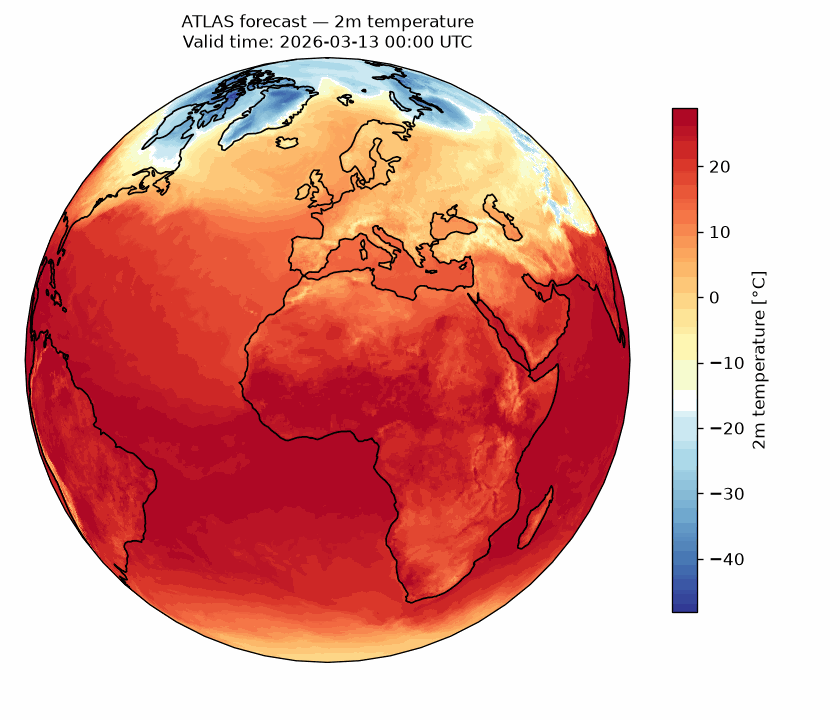

'outputs/atlas_t2m.gif'

In [8]:
render_rotating_gif(
    forecast["t2m"],
    out_path=f"outputs/{MODEL}_t2m.gif",
    title=f"{MODEL.upper()} forecast — 2m temperature",
    unit_label="2m temperature [°C]",
    convert_fn=lambda da: da - 273.15, 
    display=True,
)

## Plot RMSE

In [ ]:
path = f"outputs/{model}_forecast.zarr"
forecast = load_forecast(path)
truth = fetch_truth(data_source, "t2m", forecast["valid_time"].values)
rmse = compute_rmse(forecast, truth, "t2m")
plot_rmse(rmse, "t2m", model, out_path=f"outputs/{model}_t2m_rmse.png")
print(rmse)

In [ ]:
error = compute_difference(forecast, truth, "t2m")
render_rotating_gif(
    error,
    out_path=f"outputs/{MODEL}_t2m_error.gif",
    title=f"{MODEL.upper()} error (forecast \u2212 ERA5) \u2014 2m temperature",
    unit_label="2m temperature error [K]",
    cmap="RdBu_r",
    center=0,
    display=True,
)

In [1]:
## 

In [5]:
import xarray as xr
import numpy as np 
ds = xr.open_zarr("outputs/smoke.zarr"); t = ds.t2m
print(dict(ds.sizes))            # expect lead_time=41, ensemble=2, lat=53, lon=73
print(float(t.min()), float(t.max()))   # Kelvin, roughly 270-315 over France in August
# spread across members should be ~0 at lead 0 and grow with lead time
print(t.isel(time=0, lead_time=[0, 4, 12, 39]).std("ensemble", ddof=1).mean(("lat", "lon")).values)

print(ds.lead_time.values[[0, 1, -1]] / np.timedelta64(1, "h"))   # expect [6, 12, 240]

{'time': 1, 'lead_time': 40, 'ensemble': 2, 'lat': 53, 'lon': 73}
270.8878479003906 313.89654541015625
[0.34389362 0.38908285 0.5450608  1.0426728 ]
[  6.  12. 240.]


In [6]:
import numpy as np, pandas as pd
from weather_pipeline.datasource import build_data_source

src = build_data_source("era5")
init = pd.Timestamp(ds.time.values[0])
leads = pd.to_timedelta([6, 24, 48, 96], unit="h")
truth = (src([init + l for l in leads], ["t2m"])
         .sel(variable="t2m").sel(lat=ds.lat, lon=ds.lon, method="nearest"))
fc = ds.t2m.isel(time=0).sel(lead_time=leads).mean("ensemble")
rmse = np.sqrt(((fc.values - truth.values) ** 2).mean(axis=(1, 2)))
print(dict(zip([6, 24, 48, 96], rmse.round(2))))

{6: 0.59, 24: 0.64, 48: 0.9, 96: 1.24}


In [1]:
from weather_pipeline.stations import MeteoFranceHourly, load_stations

ds, report = load_stations(
    MeteoFranceHourly(), "france", "2026-06-01", "2026-06-30",
    variables=["t2m", "tx1h"], cache_dir="outputs/cache/stations202606",
)

In [4]:
ds, report = load_stations(MeteoFranceHourly(), (45.3, 46.0, 4.5, 5.2),
                           "2023-08-20", "2023-08-22 23:00", variables=["t2m"],
                           cache_dir="outputs/cache/stations_test")

In [1]:
import pandas as pd
r = pd.read_csv("outputs/m0_2023/station_qc_report.csv", index_col=0)
dropped = r[r.candidate & ~r.kept]
print(dropped.completeness.round(2).value_counts().head(10))

completeness
0.00    429
0.04      2
0.79      1
0.55      1
0.85      1
0.76      1
0.08      1
0.01      1
0.87      1
0.60      1
Name: count, dtype: int64


In [2]:
import pandas as pd
m = pd.read_csv("outputs/m0_2023/metrics_overall.csv")
m["valid_hour"] = m.lead_h % 24                     # all inits are 00 UTC
keep = ["bilinear", "bilinear_lapse", "analysis_bilinear", "analysis_bilinear_lapse"]
t = m[m.method.isin(keep)]
print(t.pivot_table(index="valid_hour", columns="method", values="bias").round(2))
print(t.pivot_table(index="valid_hour", columns="method", values="rmse").round(2))

b = pd.read_csv("outputs/m0_2023/metrics_binned.csv")
b = b[(b.region == "france") & b.method.isin(keep)]
print(b.pivot_table(index="elevation", columns="method", values="bias").round(2))

method      analysis_bilinear  analysis_bilinear_lapse  bilinear  \
valid_hour                                                         
0                        0.41                     0.55      0.39   
6                        0.30                     0.44      0.34   
12                      -0.53                    -0.39     -0.22   
18                       0.08                     0.22      0.21   

method      bilinear_lapse  
valid_hour                  
0                     0.53  
6                     0.48  
12                   -0.08  
18                    0.35  
method      analysis_bilinear  analysis_bilinear_lapse  bilinear  \
valid_hour                                                         
0                        2.00                     2.03      2.51   
6                        1.83                     2.02      2.30   
12                       2.36                     1.81      3.14   
18                       2.05                     1.53      2.75   

method  

In [1]:
import pandas as pd
d = pd.read_csv("outputs/eval_aug2025/by_lead.csv")
d["day"] = d.lead_h // 24
print(d[d.method.isin(["coarse", "downscaled"])]
      .pivot_table(index="day", columns=["method", "valid_hour"], values="rmse").round(2))

Empty DataFrame
Columns: []
Index: []


In [5]:
d.method

0              aifs
1              aifs
2              aifs
3              aifs
4              aifs
           ...     
115    aifs_on_grid
116    aifs_on_grid
117    aifs_on_grid
118    aifs_on_grid
119    aifs_on_grid
Name: method, Length: 120, dtype: str